# EDA Hate Speech

Data original dan hasil splitting EN, IT, dan NL dengan label `hate_speech`.

## Persiapan

In [1]:
from pathlib import Path
from itertools import combinations
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LANGUAGES = ["EN", "IT", "NL"]
SUBSETS = ["original", "train", "val", "test"]
LABELS = ["no", "yes_implicit", "yes_explicit"]
COLORS = ["#66c2a5", "#fc8d62", "#8da0cb"]

DATA_DIR = Path("../data")

In [2]:
# Kolom untuk EDA hate speech dan audit data.
COLUMNS = ["StereoQueerEval_id", "yt_title", "yt_description", "yt_comment", "hate_speech"]
original = {}
splits = {}
for lang in LANGUAGES:
    original[lang] = pd.read_csv(
        DATA_DIR / "original" / f"StereoQueerEval_{lang}_training.csv",
        encoding="utf-8-sig", keep_default_na=False, dtype=str, usecols=COLUMNS,
    )
    splits[lang] = {}
    for subset in ["train", "val", "test"]:
        splits[lang][subset] = pd.read_csv(
            DATA_DIR / f"{lang.lower()}-splitting" / f"{lang.lower()}-{subset}.csv",
            encoding="utf-8-sig", keep_default_na=False, dtype=str, usecols=COLUMNS,
        )

# Satu tabel gabungan agar perbandingan mudah; original dan split tetap dibedakan.
frames = []
for lang in LANGUAGES:
    frames.append(original[lang].assign(bahasa=lang, subset="original"))
    for subset, df in splits[lang].items():
        frames.append(df.assign(bahasa=lang, subset=subset))
data = pd.concat(frames, ignore_index=True)

# Normalisasi hanya untuk audit duplikasi; teks asli tidak diubah.
def normalize(text):
    return " ".join(unicodedata.normalize("NFKC", text).casefold().split())

data["komentar_normal"] = data["yt_comment"].map(normalize)
data["jumlah_karakter"] = data["yt_comment"].str.len()
data["jumlah_kata"] = data["yt_comment"].str.split().str.len()
ori = data[data["subset"] == "original"].copy()

## Data Original

In [3]:
structure = pd.DataFrame({
    "kolom": original["EN"].columns,
    "tipe_pandas": original["EN"].dtypes.astype(str).values,
})

In [4]:
structure

,kolom,tipe_pandas
0,StereoQueerEval_id,object
1,yt_title,object
2,yt_description,object
3,yt_comment,object
4,hate_speech,object


In [6]:
ori.groupby("bahasa", sort=False).head(3)[["bahasa", *COLUMNS]]

,bahasa,StereoQueerEval_id,yt_title,yt_description,yt_comment,hate_speech
0,EN,training_EN_0001,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...,yes_explicit
1,EN,training_EN_0002,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...,yes_implicit
2,EN,training_EN_0003,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall...",yes_implicit
5978,IT,training_IT_0001,"Nivan transgender a 17 anni: ""Il mio percorso ...",Nivan è un ragazzo transgender Ftm di soli 17 ...,Sono transgender ma ho paura di dirlo ai miei ...,no
5979,IT,training_IT_0002,"Casillas annuncia di essere gay, poi parla di ...","Travolto dalle polemiche, Casillas è stato cos...",E cosa sarà mai guardate cosa succede nel mond...,yes_implicit
5980,IT,training_IT_0003,Schlein: «Con governo Meloni l’Italia è scivol...,«Sono sempre felice quando c’è il riconoscimen...,Ma fate silenzio il gay pride e finito ora and...,yes_explicit
10778,NL,training_NL_0001,Non-binaire mensen kunnen binnenkort vragen om...,Binnenkort kunnen non-binaire mensen vragen om...,een schande dat ons geld hier naartoe gaat,yes_implicit
10779,NL,training_NL_0002,Non-binaire mensen kunnen binnenkort vragen om...,Binnenkort kunnen non-binaire mensen vragen om...,"Ach shit,...et is idd 1 april natuurlijk😂....",yes_implicit
10780,NL,training_NL_0003,Acceptatie lhbti+ op dieptepunt! ’Social media...,Ooit was Nederland een tolerant land en de hom...,"Nee, dit accepteren we niet.",yes_implicit


In [7]:
summary = ori.groupby("bahasa").agg(
    jumlah_baris=("StereoQueerEval_id", "size"),
    id_unik=("StereoQueerEval_id", "nunique"),
    komentar_unik=("yt_comment", "nunique"),
    komentar_unik_normal=("komentar_normal", "nunique"),
    rata_rata_kata=("jumlah_kata", "mean"),
    median_kata=("jumlah_kata", "median"),
).reindex(LANGUAGES)

In [8]:
summary.round(2)

,jumlah_baris,id_unik,komentar_unik,komentar_unik_normal,rata_rata_kata,median_kata
bahasa,,,,,,
EN,2989,2989,2989,2989,29.20,17.0
IT,2400,2400,2399,2399,24.69,15.0
NL,2238,2238,2238,2238,25.16,15.0


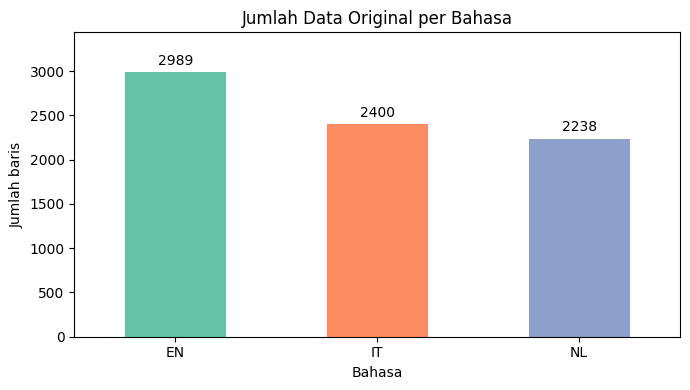

In [9]:
ax = summary["jumlah_baris"].plot.bar(color=COLORS, rot=0, figsize=(7, 4))
ax.bar_label(ax.containers[0], padding=3)
ax.set(title="Jumlah Data Original per Bahasa", xlabel="Bahasa", ylabel="Jumlah baris")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

### Nilai Kosong dan Duplikasi

In [10]:
missing_rows = []
quality_rows = []
for lang, df in original.items():
    missing = df.isna() | df.apply(lambda col: col.str.strip().eq(""))
    missing_rows.append(missing.sum().rename(lang))
    comments = df["yt_comment"].map(normalize)
    conflict = pd.DataFrame({"komentar": comments, "label": df["hate_speech"]})
    quality_rows.append({
        "bahasa": lang,
        "baris_duplikat_penuh": df.duplicated().sum(),
        "id_duplikat": df["StereoQueerEval_id"].duplicated().sum(),
        "komentar_duplikat_normal": comments.duplicated().sum(),
        "komentar_dengan_label_berbeda": (conflict.groupby("komentar")["label"].nunique() > 1).sum(),
        "label_tidak_dikenal": (~df["hate_speech"].isin(LABELS)).sum(),
    })
missing_table = pd.DataFrame(missing_rows)

In [11]:
missing_table

,StereoQueerEval_id,yt_title,yt_description,yt_comment,hate_speech
EN,0,0,0,0,0
IT,0,0,0,0,0
NL,0,0,0,0,0


In [12]:
pd.DataFrame(quality_rows).set_index("bahasa")

,baris_duplikat_penuh,id_duplikat,komentar_duplikat_normal,komentar_dengan_label_berbeda,label_tidak_dikenal
bahasa,,,,,
EN,0,0,0,0,0
IT,0,0,1,0,0
NL,0,0,0,0,0


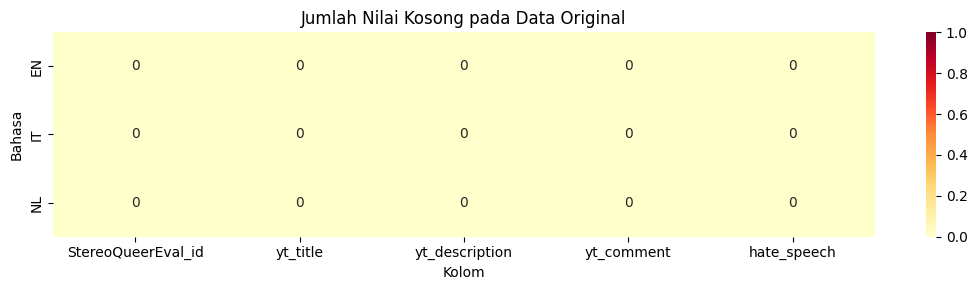

In [13]:
plt.figure(figsize=(11, 3))
sns.heatmap(missing_table, annot=True, fmt="d", cmap="YlOrRd", vmin=0, vmax=max(1, int(missing_table.to_numpy().max())))
plt.title("Jumlah Nilai Kosong pada Data Original")
plt.xlabel("Kolom")
plt.ylabel("Bahasa")
plt.tight_layout()
plt.show()

## Distribusi Label

In [14]:
label_counts = pd.crosstab(ori["bahasa"], ori["hate_speech"]).reindex(index=LANGUAGES, columns=LABELS, fill_value=0)
label_pct = label_counts.div(label_counts.sum(axis=1), axis=0) * 100

In [15]:
label_counts

hate_speech,no,yes_implicit,yes_explicit
bahasa,,,
EN,1407,772,810
IT,1160,581,659
NL,1127,487,624


In [16]:
label_pct.round(2).rename_axis(columns="label (%)")

label (%),no,yes_implicit,yes_explicit
bahasa,,,
EN,47.07,25.83,27.10
IT,48.33,24.21,27.46
NL,50.36,21.76,27.88


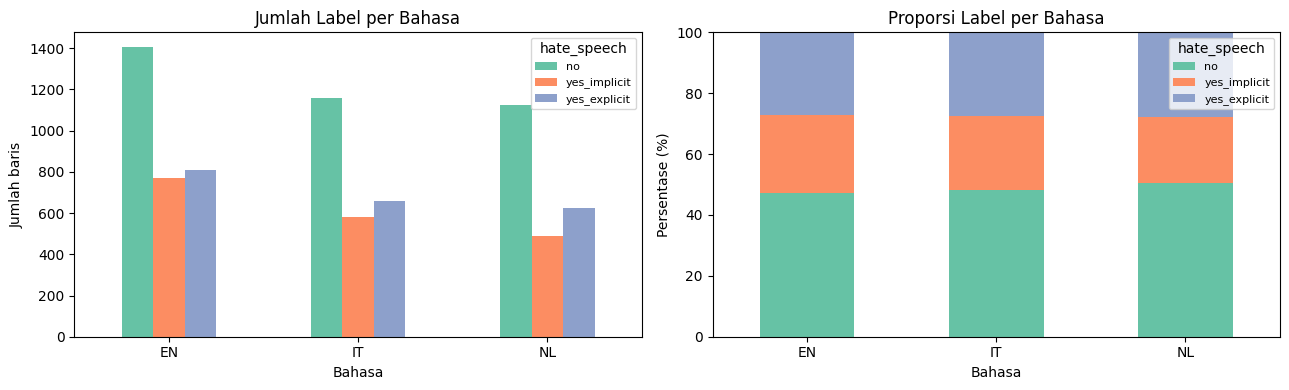

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
label_counts.plot.bar(ax=axes[0], color=COLORS, rot=0)
label_pct.plot.bar(stacked=True, ax=axes[1], color=COLORS, rot=0)
axes[0].set(title="Jumlah Label per Bahasa", xlabel="Bahasa", ylabel="Jumlah baris")
axes[1].set(title="Proporsi Label per Bahasa", xlabel="Bahasa", ylabel="Persentase (%)", ylim=(0, 100))
for ax in axes:
    ax.legend(title="hate_speech", fontsize=8)
plt.tight_layout()
plt.show()

## Panjang Komentar

Panjang dihitung dalam karakter dan kata. Histogram ditampilkan hingga P99.

In [18]:
length_stats = ori.groupby("bahasa")[["jumlah_karakter", "jumlah_kata"]].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])

In [19]:
length_stats.round(2)

jumlah_karakter                                                    \
                 count    mean     std  min    25%   50%     75%     95%   
bahasa                                                                     
EN              2989.0  160.94  217.63  4.0  49.00  91.0  180.00  519.80   
IT              2400.0  146.52  188.91  6.0  45.00  86.0  168.25  456.30   
NL              2238.0  139.55  180.16  4.0  45.25  84.0  157.00  449.45   

                        jumlah_kata                                            \
            99%     max       count   mean    std  min  25%   50%   75%   95%   
bahasa                                                                          
EN       982.72  3477.0      2989.0  29.20  38.66  1.0  9.0  17.0  33.0  96.0   
IT      1051.11  2087.0      2400.0  24.69  31.60  1.0  8.0  15.0  29.0  78.0   
NL       824.78  2296.0      2238.0  25.16  31.71  1.0  8.0  15.0  28.0  80.0   

                       
           99%    max  
bahasa                 
EN      179.00  496.0  
IT      163.01  340.0  
NL      144.26  404.0

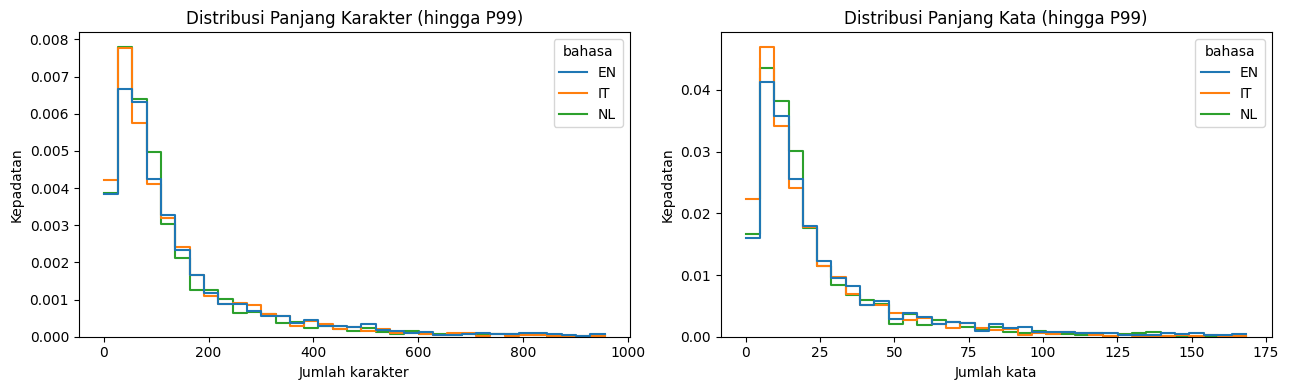

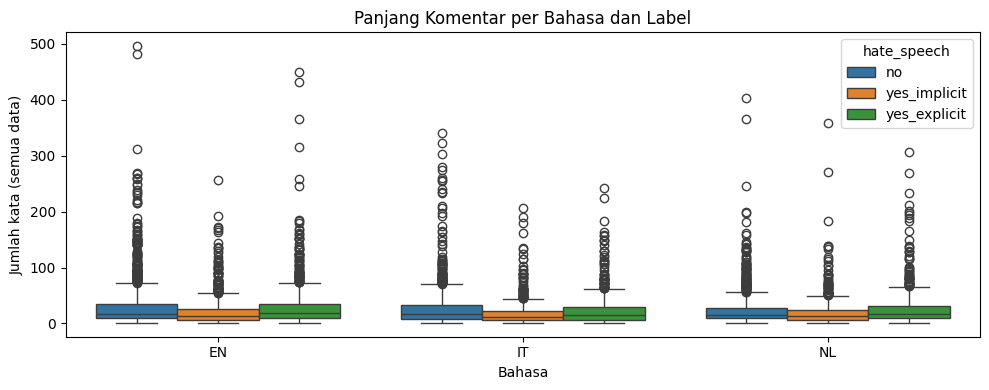

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column, title in zip(axes, ["jumlah_karakter", "jumlah_kata"], ["Karakter", "Kata"]):
    limit = ori[column].quantile(0.99)
    sns.histplot(data=ori, x=column, hue="bahasa", hue_order=LANGUAGES,
                 bins=35, binrange=(0, limit), stat="density", common_norm=False,
                 element="step", fill=False, ax=ax)
    ax.set(title=f"Distribusi Panjang {title} (hingga P99)", xlabel=f"Jumlah {title.lower()}", ylabel="Kepadatan")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(data=ori, x="bahasa", y="jumlah_kata", hue="hate_speech", order=LANGUAGES, hue_order=LABELS)
plt.title("Panjang Komentar per Bahasa dan Label")
plt.xlabel("Bahasa")
plt.ylabel("Jumlah kata (semua data)")
plt.tight_layout()
plt.show()

## Hasil Splitting

In [21]:
split_data = data[data["subset"] != "original"].copy()
split_counts = pd.crosstab(split_data["bahasa"], split_data["subset"]).reindex(index=LANGUAGES, columns=["train", "val", "test"], fill_value=0)
split_pct = split_counts.div(summary["jumlah_baris"], axis=0) * 100

In [22]:
split_counts

subset,train,val,test
bahasa,,,
EN,2111,292,586
IT,1699,220,481
NL,1556,226,456


In [23]:
split_pct.round(2).rename_axis(columns="subset (%)")

subset (%),train,val,test
bahasa,,,
EN,70.63,9.77,19.61
IT,70.79,9.17,20.04
NL,69.53,10.10,20.38


In [24]:
split_pct.sub(pd.Series({"train": 70, "val": 10, "test": 20}), axis=1).round(2).rename_axis(columns="selisih dari target (poin persentase)")

selisih dari target (poin persentase),train,val,test
bahasa,,,
EN,0.63,-0.23,-0.39
IT,0.79,-0.83,0.04
NL,-0.47,0.10,0.38


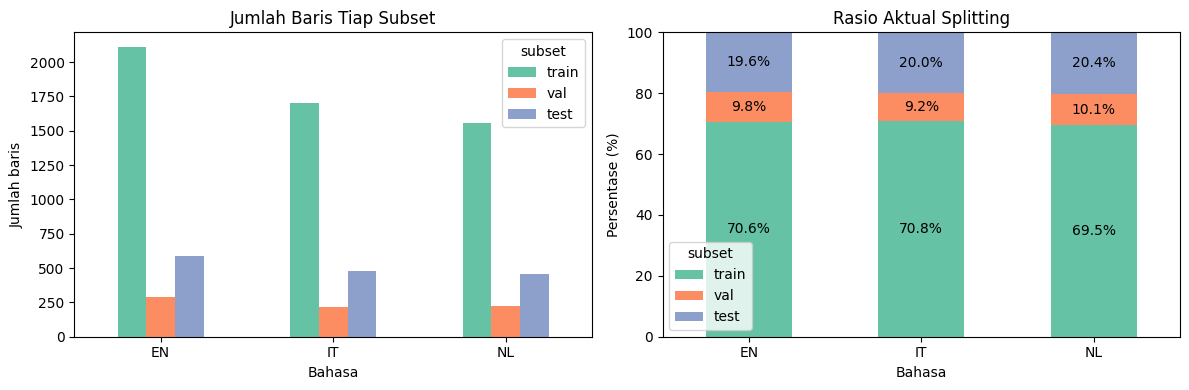

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split_counts.plot.bar(ax=axes[0], rot=0, color=COLORS)
split_pct.plot.bar(stacked=True, ax=axes[1], rot=0, color=COLORS)
axes[0].set(title="Jumlah Baris Tiap Subset", xlabel="Bahasa", ylabel="Jumlah baris")
axes[1].set(title="Rasio Aktual Splitting", xlabel="Bahasa", ylabel="Persentase (%)", ylim=(0, 100))
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", label_type="center")
plt.tight_layout()
plt.show()

## Perbandingan Label

Selisih proporsi ditampilkan dalam poin persentase.

In [26]:
index = pd.MultiIndex.from_product([LANGUAGES, SUBSETS], names=["bahasa", "subset"])
counts = pd.crosstab([data["bahasa"], data["subset"]], data["hate_speech"]).reindex(index=index, columns=LABELS, fill_value=0)
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

In [27]:
counts

hate_speech        no  yes_implicit  yes_explicit
bahasa subset                                    
EN     original  1407           772           810
       train      983           546           582
       val        147            70            75
       test       277           156           153
IT     original  1160           581           659
       train      822           401           476
       val        105            56            59
       test       233           124           124
NL     original  1127           487           624
       train      784           335           437
       val        109            55            62
       test       234            97           125

In [28]:
percentages.round(2)

hate_speech         no  yes_implicit  yes_explicit
bahasa subset                                     
EN     original  47.07         25.83         27.10
       train     46.57         25.86         27.57
       val       50.34         23.97         25.68
       test      47.27         26.62         26.11
IT     original  48.33         24.21         27.46
       train     48.38         23.60         28.02
       val       47.73         25.45         26.82
       test      48.44         25.78         25.78
NL     original  50.36         21.76         27.88
       train     50.39         21.53         28.08
       val       48.23         24.34         27.43
       test      51.32         21.27         27.41

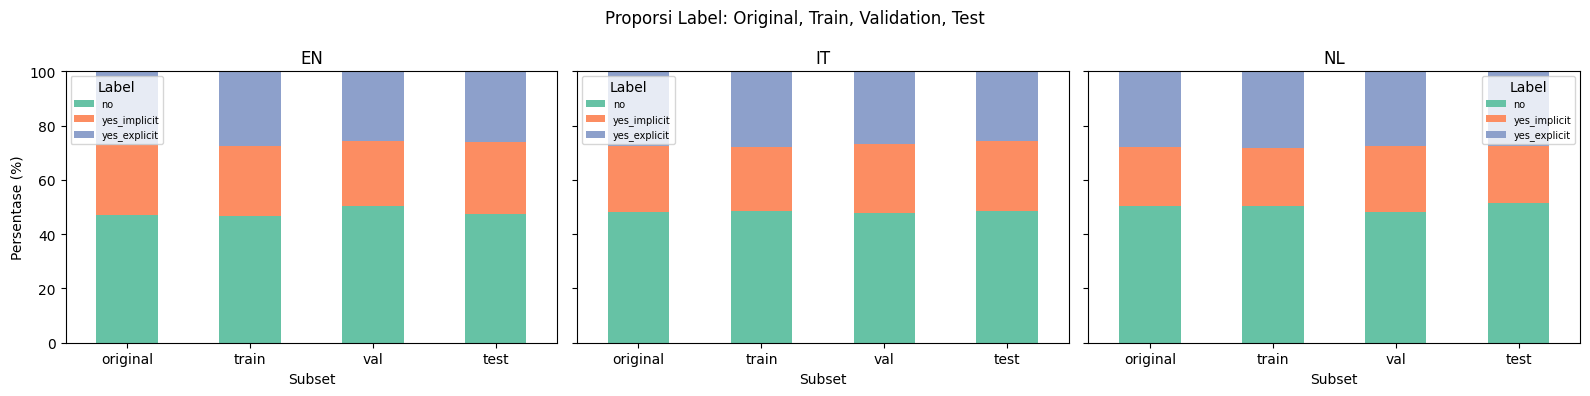

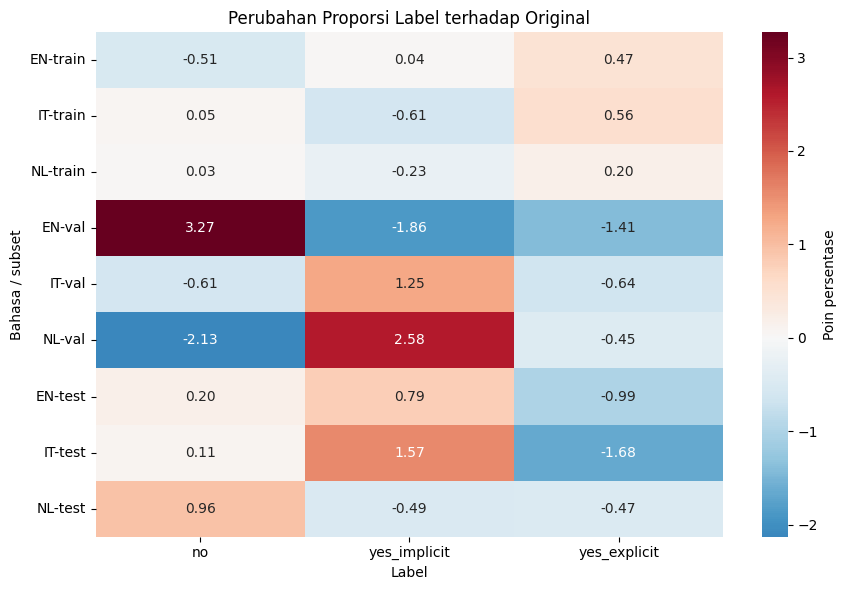

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, lang in zip(axes, LANGUAGES):
    percentages.loc[lang].plot.bar(stacked=True, ax=ax, color=COLORS, rot=0)
    ax.set(title=lang, xlabel="Subset", ylabel="Persentase (%)", ylim=(0, 100))
    ax.legend(fontsize=7, title="Label")
fig.suptitle("Proporsi Label: Original, Train, Validation, Test")
plt.tight_layout()
plt.show()

changes = percentages.copy()
for lang in LANGUAGES:
    changes.loc[lang, :] = (percentages.loc[lang] - percentages.loc[(lang, "original")]).to_numpy()
changes = changes.loc[(slice(None), ["train", "val", "test"]), :]
plt.figure(figsize=(9, 6))
sns.heatmap(changes, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "Poin persentase"})
plt.title("Perubahan Proporsi Label terhadap Original")
plt.xlabel("Label")
plt.ylabel("Bahasa / subset")
plt.tight_layout()
plt.show()

## Panjang dan Kualitas Data Split

In [30]:
subset_stats = data.groupby(["bahasa", "subset"]).agg(
    baris=("yt_comment", "size"),
    rata_rata_kata=("jumlah_kata", "mean"),
    median_kata=("jumlah_kata", "median"),
    p95_kata=("jumlah_kata", lambda values: values.quantile(0.95)),
    maksimum_kata=("jumlah_kata", "max"),
    rata_rata_karakter=("jumlah_karakter", "mean"),
).reindex(index)

In [31]:
subset_stats.round(2)

baris  rata_rata_kata  median_kata  p95_kata  maksimum_kata  \
bahasa subset                                                                  
EN     original   2989           29.20         17.0     96.00            496   
       train      2111           30.04         17.0    100.50            496   
       val         292           22.13         15.0     61.45            247   
       test        586           29.66         17.0     95.25            449   
IT     original   2400           24.69         15.0     78.00            340   
       train      1699           25.06         15.0     81.00            340   
       val         220           24.26         15.0     73.00            304   
       test        481           23.56         14.0     77.00            234   
NL     original   2238           25.16         15.0     80.00            404   
       train      1556           26.12         16.0     82.00            404   
       val         226           23.40         15.0     70.25            200   
       test        456           22.76         15.0     70.25            366   

                 rata_rata_karakter  
bahasa subset                        
EN     original              160.94  
       train                 165.58  
       val                   121.73  
       test                  163.75  
IT     original              146.52  
       train                 148.75  
       val                   142.81  
       test                  140.37  
NL     original              139.55  
       train                 144.89  
       val                   130.64  
       test                  125.74

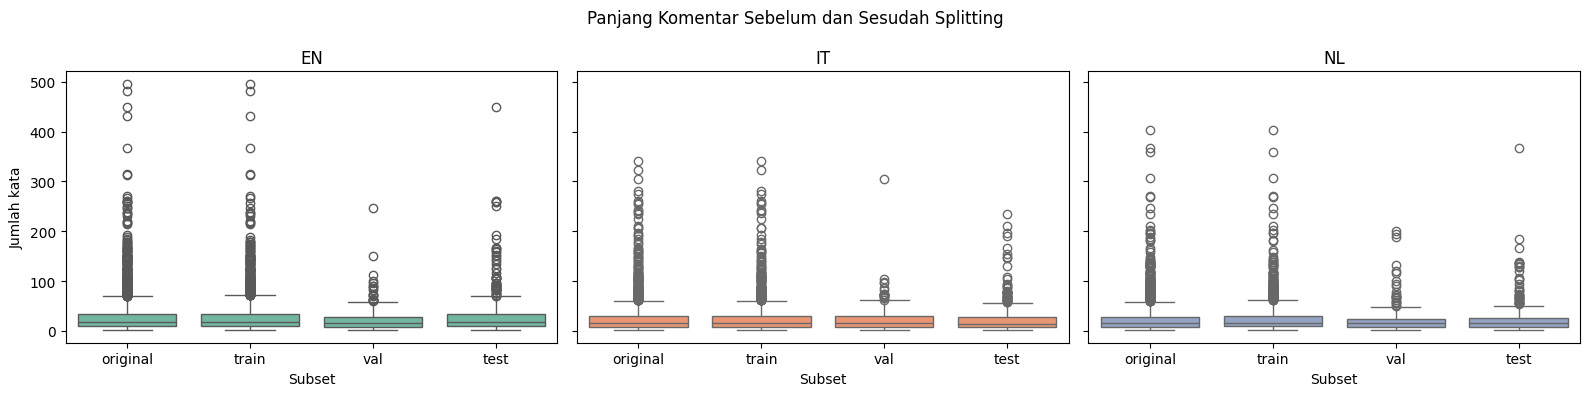

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, lang in zip(axes, LANGUAGES):
    sns.boxplot(data=data[data["bahasa"] == lang], x="subset", y="jumlah_kata", order=SUBSETS, ax=ax, color=COLORS[LANGUAGES.index(lang)])
    ax.set(title=lang, xlabel="Subset", ylabel="Jumlah kata")
fig.suptitle("Panjang Komentar Sebelum dan Sesudah Splitting")
plt.tight_layout()
plt.show()

quality = []
for lang in LANGUAGES:
    for subset, df in splits[lang].items():
        empty = df.isna() | df.apply(lambda col: col.str.strip().eq(""))
        quality.append({
            "bahasa": lang, "subset": subset,
            "sel_kosong": empty.sum().sum(),
            "id_duplikat": df["StereoQueerEval_id"].duplicated().sum(),
            "komentar_duplikat_normal": df["yt_comment"].map(normalize).duplicated().sum(),
            "jumlah_kelas": df["hate_speech"].nunique(),
            "semua_label_valid": df["hate_speech"].isin(LABELS).all(),
        })

In [33]:
pd.DataFrame(quality).set_index(["bahasa", "subset"])

sel_kosong  id_duplikat  komentar_duplikat_normal  \
bahasa subset                                                      
EN     train            0            0                         0   
       val              0            0                         0   
       test             0            0                         0   
IT     train            0            0                         1   
       val              0            0                         0   
       test             0            0                         0   
NL     train            0            0                         0   
       val              0            0                         0   
       test             0            0                         0   

               jumlah_kelas  semua_label_valid  
bahasa subset                                   
EN     train              3               True  
       val                3               True  
       test               3               True  
IT     train              3               True  
       val                3               True  
       test               3               True  
NL     train              3               True  
       val                3               True  
       test               3               True

## Kelengkapan dan Overlap

Overlap ID, komentar, dan konteks antar-subset diharapkan 0.

In [34]:
coverage_rows = []
overlap_rows = []
for lang in LANGUAGES:
    source = original[lang]
    merged = pd.concat(splits[lang].values(), ignore_index=True)
    columns = list(source.columns)
    source_sorted = source.sort_values("StereoQueerEval_id").reset_index(drop=True)
    merged_sorted = merged.reindex(columns=columns).sort_values("StereoQueerEval_id").reset_index(drop=True)
    coverage_rows.append({
        "bahasa": lang,
        "baris_original": len(source), "total_baris_split": len(merged),
        "id_hilang": len(set(source["StereoQueerEval_id"]) - set(merged["StereoQueerEval_id"])),
        "id_tambahan": len(set(merged["StereoQueerEval_id"]) - set(source["StereoQueerEval_id"])),
        "id_berulang_di_gabungan": merged["StereoQueerEval_id"].duplicated().sum(),
        "semua_isi_identik": source_sorted.equals(merged_sorted),
    })
    keys = {}
    for subset, df in splits[lang].items():
        contexts = zip(df["yt_title"].map(normalize), df["yt_description"].map(normalize))
        keys[subset] = {
            "id": set(df["StereoQueerEval_id"]),
            "komentar": set(df["yt_comment"].map(normalize)),
            "konteks": {pair for pair in contexts if any(pair)},
        }
    for left, right in combinations(["train", "val", "test"], 2):
        overlap_rows.append({
            "bahasa": lang, "pasangan": f"{left} / {right}",
            **{name: len(keys[left][name] & keys[right][name]) for name in ["id", "komentar", "konteks"]},
        })
coverage = pd.DataFrame(coverage_rows).set_index("bahasa")
overlap = pd.DataFrame(overlap_rows).set_index(["bahasa", "pasangan"])

In [35]:
coverage

,baris_original,total_baris_split,id_hilang,id_tambahan,id_berulang_di_gabungan,semua_isi_identik
bahasa,,,,,,
EN,2989,2989,0,0,0,True
IT,2400,2400,0,0,0,True
NL,2238,2238,0,0,0,True


In [36]:
overlap

id  komentar  konteks
bahasa pasangan                           
EN     train / val    0         0        0
       train / test   0         0        0
       val / test     0         0        0
IT     train / val    0         0        0
       train / test   0         0        0
       val / test     0         0        0
NL     train / val    0         0        0
       train / test   0         0        0
       val / test     0         0        0

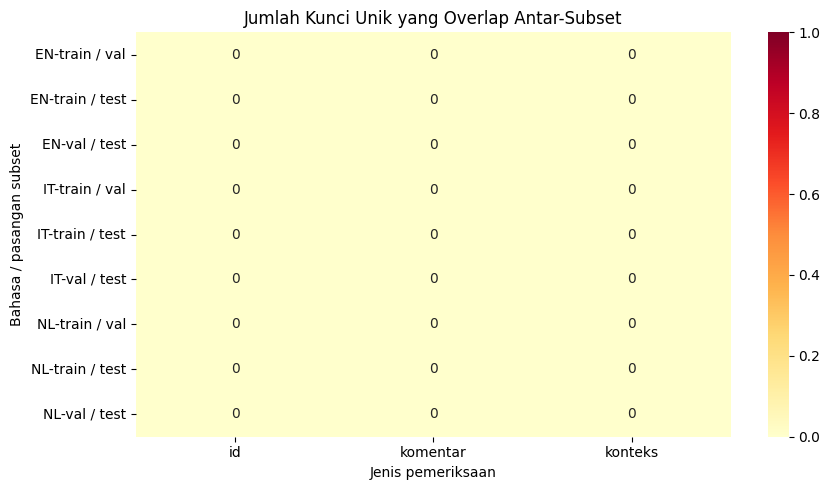

In [37]:
plt.figure(figsize=(9, 5))
sns.heatmap(overlap, annot=True, fmt="d", cmap="YlOrRd", vmin=0, vmax=max(1, int(overlap.to_numpy().max())))
plt.title("Jumlah Kunci Unik yang Overlap Antar-Subset")
plt.xlabel("Jenis pemeriksaan")
plt.ylabel("Bahasa / pasangan subset")
plt.tight_layout()
plt.show()